In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path
from sklearn.metrics import f1_score

In [ ]:
# ==========================================================
# Directories
# ==========================================================
DIR_DATA = Path("/content/drive/MyDrive/School/University-of-Guelph/MDS/Course/26-2S_DATA6700/1_data/")
DIR_METADATA = DIR_DATA / "0_metadata"
DIR_ZSCORE = DIR_DATA / "2_processed" / "4_ICEYE_Zscore"
DIR_ICEYE_MASK = DIR_DATA / "1-5_intermediate" / "4_ICEYE_Zscore_mask"
DIR_EVAL = DIR_DATA / "4_evaluation"

FILEPATH_ICEYE_LIST = DIR_METADATA / "iceye-list-full.csv"
FILEPATH_PATCH_CENTERS = DIR_METADATA / "patch-centers.csv"

# ## Thresholds
z_thresholds = np.arange(-3.0, 3.0, 0.1)
ratio_thresholds = np.arange(0.00, 1.10, 0.10)

In [ ]:
# ==========================================================
# Read metadata
# ==========================================================
iceye_df = pd.read_csv(FILEPATH_ICEYE_LIST)
patch_df = pd.read_csv(FILEPATH_PATCH_CENTERS)

iceye_df = iceye_df[
    iceye_df["zscore_mask"] == True
].copy()

patch_df = patch_df[
    patch_df["usage"] == "test"
].copy()

print(f"{len(iceye_df)} images")
print(f"{len(patch_df)} patches")

records = []

for _, iceye_row in iceye_df.iterrows():
    label = int(iceye_row["wet"] == 1.0)

    image_id = iceye_row["iceye_id"]
    directory = iceye_row["dirname"]

    print(f"\nProcessing image {image_id}")

    image_dir = DIR_ZSCORE / directory
    mask_dir = DIR_ICEYE_MASK / directory

    for _, row in patch_df.iterrows():
        patch_id = row["id"]
        print(f"Processing patch {patch_id}")

        zscore_path = (
            image_dir
            / f"z_{image_id}_{patch_id}.tif"
        )

        mask_path = (
            mask_dir
            / f"z_{image_id}_{patch_id}_mask.tif"
        )

        if not zscore_path.exists():
            print(f"Skipping {zscore_path}")
            continue

        if not mask_path.exists():
            print(f"Skipping {mask_path}")
            continue

        # ---------------------------------------
        # Read Z-score
        # ---------------------------------------

        with rasterio.open(zscore_path) as src:
            zscore = src.read(1)

        # ---------------------------------------
        # Read evidence mask
        # ---------------------------------------

        with rasterio.open(mask_path) as src:
            evidence_mask = src.read(1).astype(bool)

        # ---------------------------------------
        # Extract only evidence pixels
        # ---------------------------------------

        evidence_z = zscore[evidence_mask]

        # Remove NaN / infinite values
        evidence_z = evidence_z[
            np.isfinite(evidence_z)
        ]

        # if len(evidence_z) == 0:
        #     print(f"Skipping {zscore_path}")
        #     continue
        print(len(evidence_z))

        records.append({
            "image_id": image_id,
            "patch_id": patch_id,
            "label": label,
            "zscore": evidence_z,
        })

    print(f"{len(records)} patches loaded.")

In [ ]:
ratio_data = []

for record in records:
    for z_threshold in z_thresholds:
        if len(record["zscore"]) == 0:
            dark_ratio = 0.0
        else:
            dark_ratio = np.mean(
                record["zscore"] < z_threshold
            )

        ratio_data.append({
            "image_id": record["image_id"],
            "patch_id": record["patch_id"],
            "label": record["label"],
            "z_threshold": z_threshold,
            "dark_ratio": dark_ratio,
        })

ratio_df = pd.DataFrame(ratio_data)

print(ratio_df.head())
print(ratio_df.tail())

In [ ]:
results = []

for z_threshold in z_thresholds:

    subset = ratio_df[
        ratio_df["z_threshold"] == z_threshold
    ]

    y_true = subset["label"].to_numpy()

    for ratio_threshold in ratio_thresholds:

        y_pred = (
            subset["dark_ratio"].to_numpy()
            >= ratio_threshold
        ).astype(int)

        f1 = f1_score(
            y_true,
            y_pred,
            zero_division=0,
        )

        results.append({
            "z_threshold": z_threshold,
            "ratio_threshold": ratio_threshold,
            "f1": f1,
        })

results_df = pd.DataFrame(results)

print(results_df.head(50))
print(results_df.tail(50))

In [6]:
# Find best F1-score
best_idx = results_df["f1"].idxmax()
best_result = results_df.loc[best_idx]

best_z_threshold = best_result["z_threshold"]
best_ratio_threshold = best_result["ratio_threshold"]
best_f1 = best_result["f1"]

print("Best threshold combination:")
print(f"  Z-score threshold:       {best_z_threshold:.2f}")
print(f"  Dark-pixel ratio:        {best_ratio_threshold:.2%}")
print(f"  F1-score:                {best_f1:.3f}")

Best threshold combination:
  Z-score threshold:       -3.00
  Dark-pixel ratio:        0.00%
  F1-score:                0.667


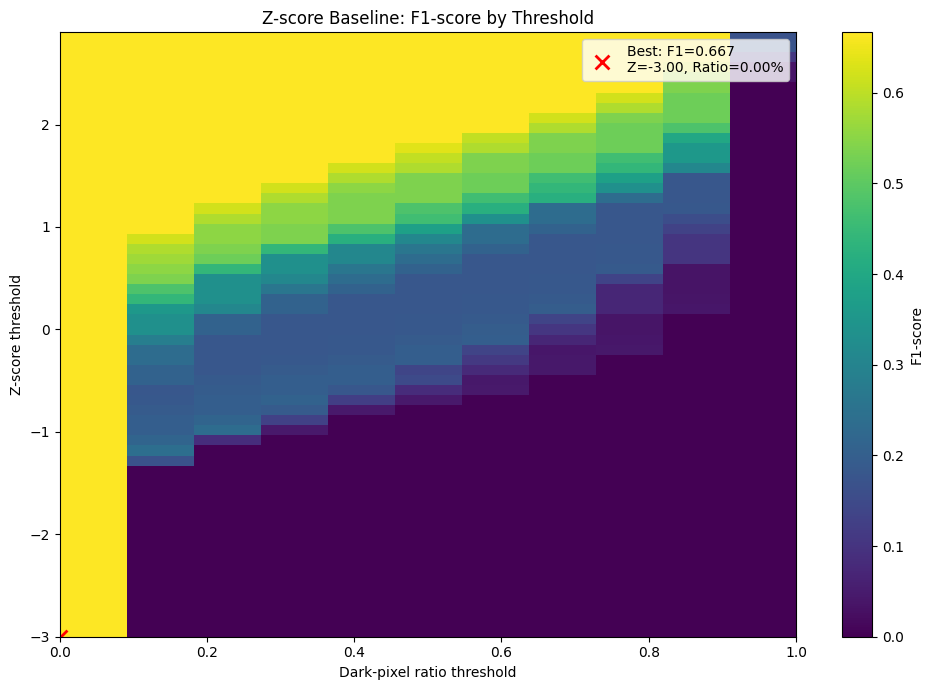

In [7]:
heatmap = results_df.pivot(
    index="z_threshold",
    columns="ratio_threshold",
    values="f1",
)

plt.figure(figsize=(10, 7))

plt.imshow(
    heatmap,
    aspect="auto",
    origin="lower",
    extent=[
        ratio_thresholds.min(),
        ratio_thresholds.max(),
        z_thresholds.min(),
        z_thresholds.max(),
    ],
)

plt.colorbar(label="F1-score")

plt.scatter(
    best_ratio_threshold,
    best_z_threshold,
    marker="x",
    s=100,
    color="red",
    linewidths=2,
    label=(
        f"Best: F1={best_f1:.3f}\n"
        f"Z={best_z_threshold:.2f}, "
        f"Ratio={best_ratio_threshold:.2%}"
    ),
)

plt.xlabel("Dark-pixel ratio threshold")
plt.ylabel("Z-score threshold")

plt.title(
    "Z-score Baseline: F1-score by Threshold"
)

plt.legend()

plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

best_idx = results_df["f1"].idxmax()
best_result = results_df.loc[best_idx]

best_z = best_result["z_threshold"]
best_ratio = best_result["ratio_threshold"]

print(f"Best Z-score threshold: {best_z:.2f}")
print(f"Best dark-pixel ratio: {best_ratio:.2%}")

Best Z-score threshold: -3.00
Best dark-pixel ratio: 0.00%


In [ ]:
best_df = ratio_df[
    ratio_df["z_threshold"] == best_z
].copy()

best_df["prediction"] = (
    best_df["dark_ratio"] >= best_ratio
).astype(int)

y_true = best_df["label"].to_numpy()
y_pred = best_df["prediction"].to_numpy()

In [ ]:
best_df = ratio_df[
    ratio_df["z_threshold"] == best_z
].copy()

best_df["prediction"] = (
    best_df["dark_ratio"] >= best_ratio
).astype(int)

y_true = best_df["label"].to_numpy()
y_pred = best_df["prediction"].to_numpy()

In [11]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true,
    y_pred,
    zero_division=0,
)
recall = recall_score(
    y_true,
    y_pred,
    zero_division=0,
)
f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0,
)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")

Accuracy : 0.500
Precision: 0.500
Recall   : 1.000
F1-score : 0.667


In [12]:
cm = confusion_matrix(
    y_true,
    y_pred,
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 0 30]
 [ 0 30]]


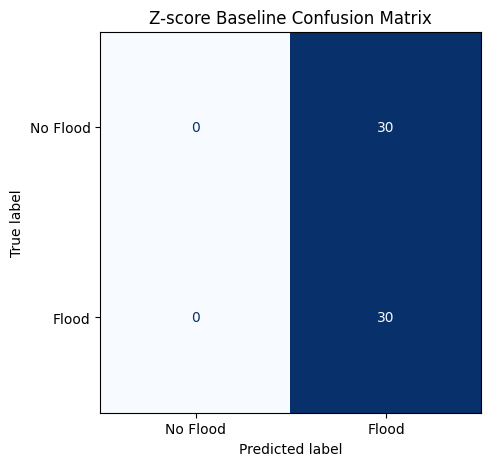

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Flood", "Flood"],
)

fig, ax = plt.subplots(figsize=(5, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
)

ax.set_title("Z-score Baseline Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
)

In [ ]:
z_threshold = 0.0

roc_records = []

for record in records:

    z_values = record["zscore"]

    dark_ratio = np.mean(
        z_values < z_threshold
    )

    roc_records.append({
        "image_id": record["image_id"],
        "patch_id": record["patch_id"],
        "label": record["label"],
        "dark_ratio": dark_ratio,
    })

roc_df = pd.DataFrame(roc_records)

In [16]:
y_true = roc_df["label"].to_numpy()
y_score = roc_df["dark_ratio"].to_numpy()

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_score,
)

auc = roc_auc_score(
    y_true,
    y_score,
)

print(f"AUC: {auc:.3f}")

AUC: 0.049


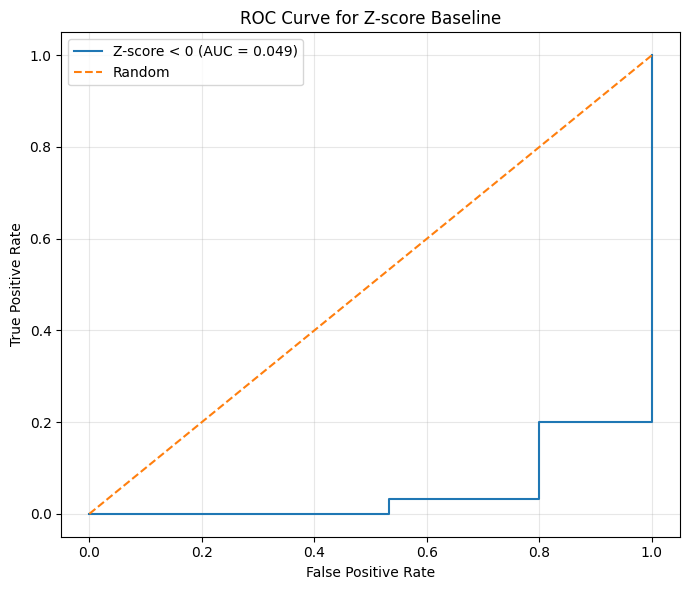

In [17]:
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Z-score < 0 (AUC = {auc:.3f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "ROC Curve for Z-score Baseline"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
print(
    roc_df.groupby("label")["dark_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
)

       count      mean    median       min       max
label                                               
0         30  0.843005  0.902562  0.439758  1.000000
1         30  0.189385  0.050231  0.002960  0.871109


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

output_dir = DIR_EVAL / "zscore_histograms_evidenced"
output_dir.mkdir(exist_ok=True)

for record in records:

    image_id = record["image_id"]
    patch_id = record["patch_id"]
    label = record["label"]

    z = record["zscore"]

    # Remove NaN and Inf
    z = z[np.isfinite(z)]

    if len(z) == 0:
        print(f"No valid pixels: {image_id} - {patch_id}")
        continue

    plt.figure(figsize=(5, 4))

    plt.hist(
        z,
        bins=50,
        range=(-4, 4),
    )

    plt.xlim(-4, 4)
    plt.ylim(0, 15000)

    label_name = "Flood" if label == 1 else "No Flood"

    plt.title(
        f"{image_id} - {patch_id} ({label_name})"
    )
    plt.xlabel("Z-score")
    plt.ylabel("Pixel Count")

    plt.tight_layout()

    plt.savefig(
        output_dir / f"{image_id}_{patch_id}.png",
        dpi=300,
    )

    plt.close()

print(
    f"Saved {len(records)} histograms to {output_dir}"
)